# Анализ продаж небольшого интернет-магазина

**Уровень:** Intern / начинающий Junior  
**Задача:** посмотреть на продажи, прибыль и категории товаров и подготовить несколько простых выводов для владельца магазина.

Данные в `data/sales_demo.csv` **синтетические, сгенерированы для учебного кейса**. Это не выгрузка реальной компании. В проекте используются базовые операции Pandas: чтение CSV, проверка данных, `groupby`, сортировка и простые графики.

## 1. Загрузка данных

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "sales_demo.csv"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["order_date"])
df.head()

,order_id,order_date,customer_id,region,category,product,quantity,unit_price,discount,sales,profit
0,ORD-00001,2025-05-14,CUST-0202,Северо-Запад,Канцелярия,Ручка,4,90,0.05,342.0,230.0
1,ORD-00001,2025-05-14,CUST-0202,Северо-Запад,Электроника,Мышь,2,900,0.00,1800.0,940.0
2,ORD-00001,2025-05-14,CUST-0202,Северо-Запад,Дом,Плед,1,2100,0.15,1785.0,765.0
3,ORD-00002,2025-08-21,CUST-0326,Центр,Канцелярия,Папка,1,250,0.00,250.0,150.0
4,ORD-00002,2025-08-21,CUST-0326,Центр,Канцелярия,Тетрадь,2,180,0.00,360.0,210.0


## 2. Первичная проверка

Сначала посмотрим на размер таблицы, типы столбцов, пропуски и дубликаты.

In [2]:
print("Строк и столбцов:", df.shape)
df.info()
print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nПолные дубликаты:", df.duplicated().sum())

Строк и столбцов: (2178, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2178 entries, 0 to 2177
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     2178 non-null   object        
 1   order_date   2178 non-null   datetime64[ns]
 2   customer_id  2178 non-null   object        
 3   region       2178 non-null   object        
 4   category     2178 non-null   object        
 5   product      2178 non-null   object        
 6   quantity     2178 non-null   int64         
 7   unit_price   2178 non-null   int64         
 8   discount     2178 non-null   float64       
 9   sales        2178 non-null   float64       
 10  profit       2178 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(5)
memory usage: 187.3+ KB

Пропуски по столбцам:
order_id       0
order_date     0
customer_id    0
region         0
category       0
product        0
quantity       0
un

## 3. Базовые показатели

Посчитаем выручку, прибыль, количество заказов и средний чек. Важно: в таблице одна строка — это товарная позиция, поэтому средний чек считаем после группировки по заказу.

In [3]:
orders = df.groupby("order_id", as_index=False).agg(order_sales=("sales", "sum"), order_profit=("profit", "sum"))

total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
orders_count = df["order_id"].nunique()
avg_order_value = orders["order_sales"].mean()

print(f"Выручка: {total_sales:,.0f} руб.")
print(f"Прибыль: {total_profit:,.0f} руб.")
print(f"Количество заказов: {orders_count:,}")
print(f"Средний чек: {avg_order_value:,.0f} руб.")

Выручка: 4,704,780 руб.
Прибыль: 1,985,772 руб.
Количество заказов: 1,250
Средний чек: 3,764 руб.


## 4. Продажи по категориям и регионам

In [4]:
category_stats = (df.groupby("category", as_index=False)
                 .agg(sales=("sales", "sum"), profit=("profit", "sum"), quantity=("quantity", "sum"))
                 .sort_values("sales", ascending=False))
category_stats

,category,sales,profit,quantity
2,Электроника,2943015.0,1096025.0,1259
0,Дом,1568580.0,776440.0,1144
1,Канцелярия,193184.5,113306.5,945


In [5]:
region_stats = (df.groupby("region", as_index=False)
               .agg(sales=("sales", "sum"), profit=("profit", "sum"))
               .sort_values("sales", ascending=False))
region_stats

,region,sales,profit
0,Северо-Запад,1323310.0,549976.0
3,Центр,1321629.0,563509.0
4,Юг,756316.5,323034.5
2,Урал,724805.5,305334.5
1,Сибирь,578718.5,243917.5


## 5. Динамика продаж по месяцам

In [6]:
df["month"] = df["order_date"].dt.to_period("M").astype(str)
monthly_sales = df.groupby("month", as_index=False)["sales"].sum()
monthly_sales.head()

,month,sales
0,2025-01,363398.5
1,2025-02,354869.0
2,2025-03,392688.0
3,2025-04,386510.5
4,2025-05,423694.0


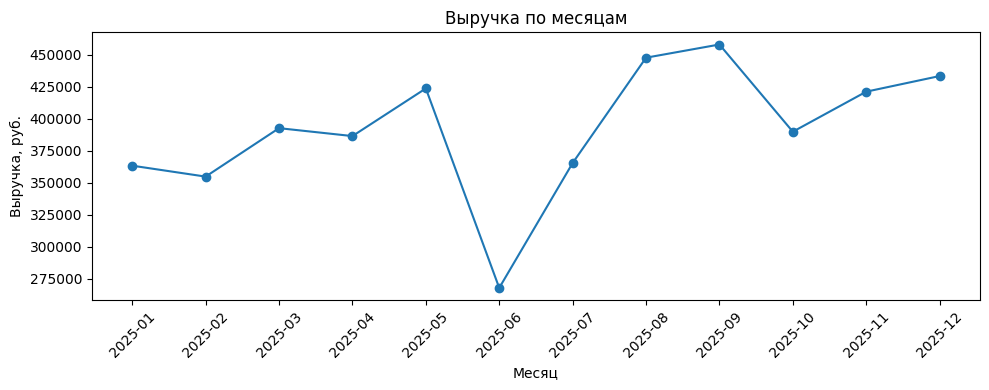

In [7]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_sales["month"], monthly_sales["sales"], marker="o")
plt.title("Выручка по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Выручка, руб.")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / "monthly_sales.png", dpi=150)
plt.show()

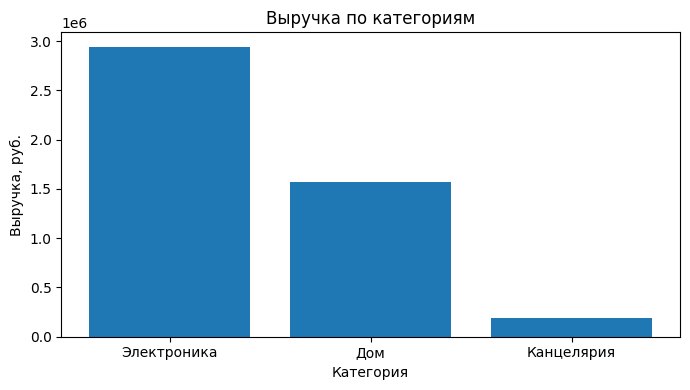

In [8]:
plt.figure(figsize=(7, 4))
plt.bar(category_stats["category"], category_stats["sales"])
plt.title("Выручка по категориям")
plt.xlabel("Категория")
plt.ylabel("Выручка, руб.")
plt.tight_layout()
plt.savefig(FIGURES / "sales_by_category.png", dpi=150)
plt.show()

## 6. Какие товары приносят меньше всего прибыли?

In [9]:
product_stats = (df.groupby("product", as_index=False)
                .agg(sales=("sales", "sum"), profit=("profit", "sum"))
                .sort_values("profit"))
product_stats.head(5)

,product,sales,profit
10,Ручка,20916.0,14028.0
11,Тетрадь,33012.0,18612.0
7,Папка,57400.0,33000.0
0,Блокнот,81856.5,47666.5
6,Органайзер,193275.0,104635.0


## 7. Простые выводы

Сводка ниже опирается на рассчитанные показатели. Различия между категориями и регионами описывают структуру продаж, но сами по себе не объясняют причины.

In [10]:
best_category = category_stats.sort_values("sales", ascending=False).iloc[0]
least_profitable_product = product_stats.iloc[0]
best_month = monthly_sales.sort_values("sales", ascending=False).iloc[0]

print(f"1. Больше всего выручки принесла категория: {best_category['category']}.")
print(f"2. Самый низкий суммарный финансовый результат среди товаров у позиции: {least_profitable_product['product']}.")
print(f"3. Самый сильный месяц по выручке: {best_month['month']}.")
print("\nЧто можно дополнительно проверить: причины низкой прибыли отдельных товаров, влияние скидок и различия между регионами.")

1. Больше всего выручки принесла категория: Электроника.
2. Самый низкий суммарный финансовый результат среди товаров у позиции: Ручка.
3. Самый сильный месяц по выручке: 2025-09.

Что можно дополнительно проверить: причины низкой прибыли отдельных товаров, влияние скидок и различия между регионами.


## 8. Что можно улучшить дальше

- Сравнить выручку и прибыль по регионам в одном графике.
- Посмотреть, как скидка связана с прибылью. Это будет наблюдение, а не доказательство причинности.
- Собрать простой дашборд в DataLens или Power BI.
- Заменить учебный CSV на публичный Sample Superstore от Tableau и повторить анализ.